# LIFE-seq Figure 4 and Extended Data Figures 1–2

Reproduce **Figure 4g–i**, **Extended Data Figure 1c–g**, and **Extended Data Figure 2a–e** from the accompanying source-data tables. Cells follow manuscript panel order. Figure 4a–f/j and Extended Data Figure 1a–b/h are outside this notebook's scope.

中文：按论文顺序展示图4g–i、扩展图1c–g和扩展图2a–e。默认使用随附数据表绘图；末尾提供从AnnData提取数据和计算差异表达的可选步骤。

The supplied tables retain the measured spot values, frozen cluster labels, fitted differential-expression results, and GO enrichment statistics. Large AnnData files are optional; no network queries or reclustering are required for the default workflow.

[Repository overview](../README.md) · [Figure guide](README.md)

中文：运行范围、输入布局和数据说明见上述文档。

In [1]:
# 中文：导入依赖并设置相对路径；默认仅显示图片。
# English: Import dependencies and configure relative paths; display figures inline by default.
from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, Circle, ConnectionPatch
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.ticker import FixedLocator, FixedFormatter
from matplotlib_venn import venn2
from scipy import stats
from scipy.spatial import cKDTree
from scipy.interpolate import make_interp_spline
from scipy.ndimage import gaussian_filter1d
from statsmodels.nonparametric.smoothers_lowess import lowess
from adjustText import adjust_text
from IPython.display import display

DATA = Path('data')
# 中文：可选输出目录；不设置时只保存 notebook 内嵌图片。
# English: Optional export directory; unset means inline output only.
EXPORT_DIR = Path(os.environ['LIFESEQ_FIGURE_OUTPUT']) if os.environ.get('LIFESEQ_FIGURE_OUTPUT') else None
mpl.rcParams.update({
    'font.family':'sans-serif', 'font.sans-serif':['Arial','DejaVu Sans'],
    'font.size':10, 'axes.linewidth':0.9, 'axes.spines.top':False,
    'axes.spines.right':False, 'pdf.fonttype':42, 'svg.fonttype':'none',
    'figure.dpi':110, 'savefig.dpi':300, 'axes.unicode_minus':False,
    'legend.frameon':False,
})

def read_table(name, **kwargs):
    return pd.read_csv(DATA/name, float_precision='round_trip', **kwargs)

def check_alignment(fig, axes):
    """Check the final rendered plot rectangles for comparable panels."""
    fig.canvas.draw()
    boxes = np.array([a.get_window_extent().bounds for a in axes])*72/fig.dpi
    if len(boxes)>1:
        for i in range(len(boxes)):
            for j in range(i):
                if abs(boxes[i,1]-boxes[j,1]) < 1.5:
                    assert abs(boxes[i,3]-boxes[j,3]) < 1.5
                if abs(boxes[i,0]-boxes[j,0]) < 1.5:
                    assert abs(boxes[i,2]-boxes[j,2]) < 1.5
    return boxes

def finish(fig, stem, comparable_axes=()):
    if len(comparable_axes):
        check_alignment(fig, comparable_axes)
    if EXPORT_DIR is not None:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EXPORT_DIR/(stem+'.pdf'), bbox_inches='tight', facecolor='white')
        fig.savefig(EXPORT_DIR/(stem+'.svg'), bbox_inches='tight', facecolor='white')
        fig.savefig(EXPORT_DIR/(stem+'.png'), dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

assert DATA.is_dir(), 'Open and run this notebook from its own directory.'


In [2]:
# 中文：读取差异表达、富集和基因顺序表，固定显示阈值。
# English: Load fitted differential-expression, enrichment and marker tables; fix display thresholds.
de = read_table('differential_expression.csv.gz')
go = read_table('GO_enrichment.csv.gz')
markers = read_table('marker_genes.csv').sort_values('display_order')
de['status'] = np.select([
    (de.pvals_adj < 0.05) & (de.logfoldchanges > 1),
    (de.pvals_adj < 0.05) & (de.logfoldchanges < -1),
], ['Up','Down'], default='Other')
assert not de.duplicated(['method','names']).any()
assert np.isfinite(de[['logfoldchanges','A_mean_normalized_counts']]).all().all()
assert (de.A_mean_normalized_counts > 0).all()
display(pd.crosstab(de.method, de.status).reindex(['section','replica']))


status,Down,Other,Up
method,,,
section,78,17078,1494
replica,203,17225,1144


## Figure 4g — Overlap of differential-expression signatures

Genes satisfy BH-adjusted P < 0.05 and |log2FC| > 1 in the corresponding spot-level Wilcoxon comparison. Predicted `Gm` identifiers are filtered by the corrected, numeric-name rule used in the final MA analysis.

中文：分别比较 Section 和 Replica 中 TBI 相对于 Sham 的上调、下调基因集合；维恩图面积由实际集合大小确定。

,Section only,Shared,Replica only
Up,632,862,282
Down,34,44,159


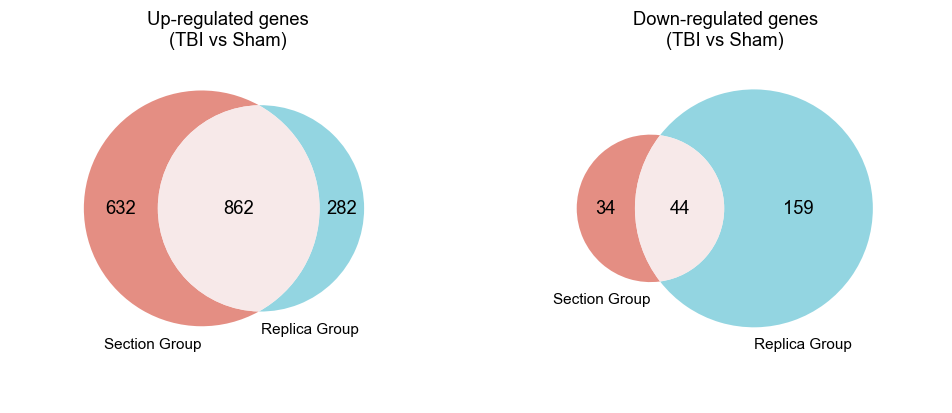

In [3]:
# 中文：绘制上调和下调基因维恩图，并计算集合交集。
# English: Plot up- and downregulated Venn diagrams and calculate set intersections.
gene_sets = {status:{m:set(de.loc[(de.method==m)&(de.status==status),'names'])
                    for m in ['section','replica']} for status in ['Up','Down']}
overlap_counts = {}
fig, axes = plt.subplots(1,2,figsize=(9,3.8))
for ax,status,title in zip(axes,['Up','Down'],['Up-regulated genes','Down-regulated genes']):
    a,b = gene_sets[status]['section'],gene_sets[status]['replica']
    overlap_counts[status] = (len(a-b),len(a&b),len(b-a))
    v=venn2([a,b],set_labels=('Section Group','Replica Group'),
            set_colors=('#E07A6D','#80CEDC'),alpha=.85,ax=ax)
    for label in v.subset_labels:
        if label is not None:label.set_fontsize(12)
    for label in v.set_labels:
        if label is not None:label.set_fontsize(10)
    ax.set_title(title+'\n(TBI vs Sham)',fontsize=12,pad=10)
    ax.set_xlim(-.95,.95);ax.set_ylim(-.85,.65);ax.set_aspect('equal')
fig.subplots_adjust(left=.03,right=.97,bottom=.05,top=.88,wspace=.15)
assert overlap_counts=={'Up':(632,862,282),'Down':(34,44,159)}
display(pd.DataFrame(overlap_counts,index=['Section only','Shared','Replica only']).T)
finish(fig,'Figure4g_DE_overlap',axes)


## Figure 4h — Cluster 3 marker-expression distributions

The first 20 genes in the saved Section-derived marker list are displayed in the same order for TBI-section and TBI-replica. Values are the original regressed/scaled `X` values from the four-capture preprocessed object, with its frozen Leiden labels.

中文：沿用原来的20个标志基因及 Cluster 3 标签，比较 Cluster 3 与其他 spots。纵轴可出现负值，因为这里使用的是回归和标准化后的表达矩阵。

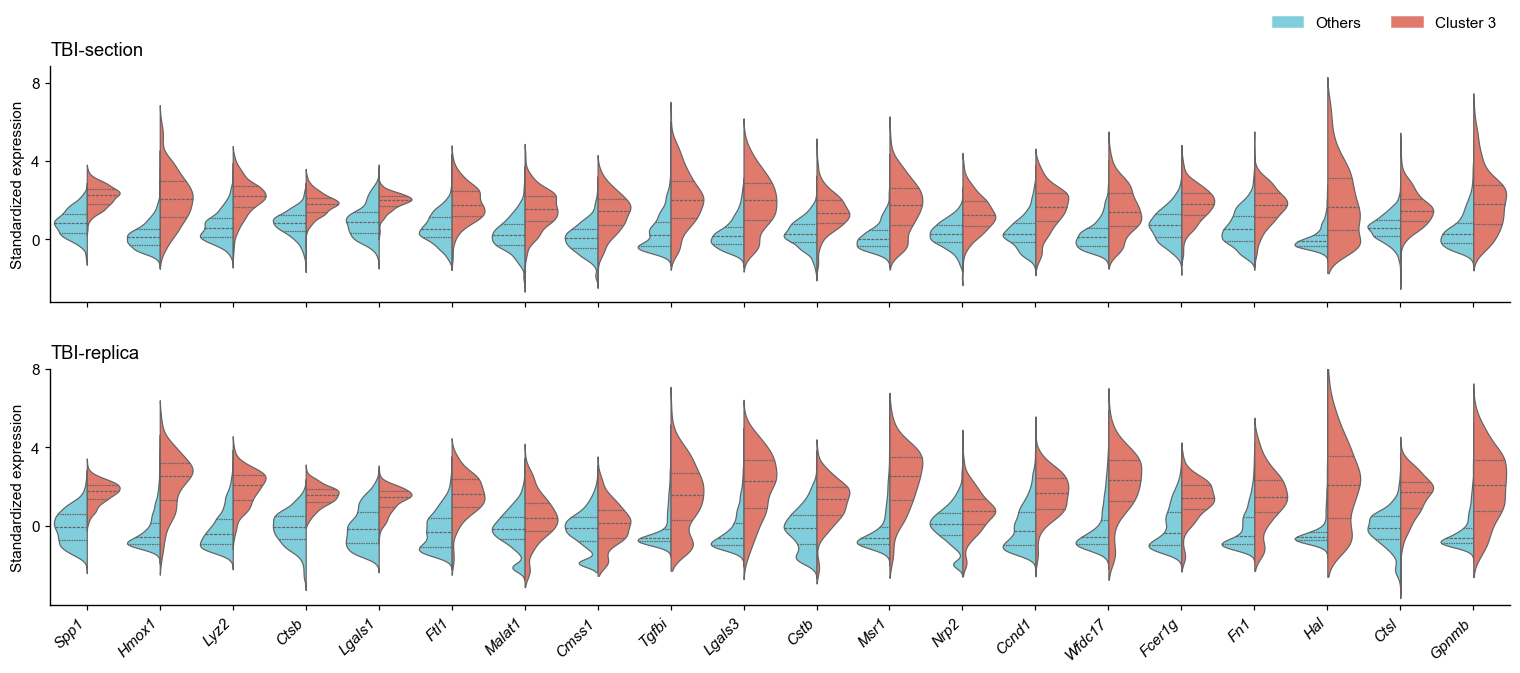

In [4]:
# 中文：按相同基因顺序绘制两个 TBI 样本的分裂小提琴图。
# English: Draw split violins for the two TBI captures using the same marker order.
violin = read_table('marker_expression.csv.gz',dtype={'batch':str,'leiden':str})
marker_order = markers.Gene.tolist()[:20]
assert set(marker_order) <= set(violin.columns)
violin['Group'] = np.where(violin.leiden=='3','Cluster 3','Others')
long = violin.melt(id_vars=['spot_id','batch','leiden','Group'],value_vars=marker_order,
                   var_name='Gene',value_name='Expression')
fig,axes=plt.subplots(2,1,figsize=(14.5,6.8),sharex=True)
for ax,b,label in zip(axes,['3','4'],['TBI-section','TBI-replica']):
    sns.violinplot(data=long[long.batch==b],x='Gene',y='Expression',hue='Group',
                   order=marker_order,hue_order=['Others','Cluster 3'],split=True,
                   inner='quartile',linewidth=.8,palette={'Others':'#80CEDC','Cluster 3':'#E07A6D'},
                   density_norm='width',saturation=1,width=.9,ax=ax)
    ax.set_title(label,loc='left',fontsize=12,pad=7)
    ax.set_xlabel('');ax.set_ylabel('Standardized expression',fontsize=10)
    ax.set_yticks([0,4,8]);ax.legend_.remove()
axes[1].set_ylim(-4,8)
axes[1].tick_params(axis='x',labelrotation=45)
for label in axes[1].get_xticklabels():label.set_ha('right');label.set_fontstyle('italic')
fig.legend([Rectangle((0,0),1,1,color='#80CEDC'),Rectangle((0,0),1,1,color='#E07A6D')],
           ['Others','Cluster 3'],loc='upper right',bbox_to_anchor=(.985,.995),ncol=2)
fig.subplots_adjust(left=.07,right=.985,top=.91,bottom=.19,hspace=.28)
finish(fig,'Figure4h_cluster3_markers',axes)


In [5]:
# 中文：定义 GO 条目选择规则、分组顺序和FDR显示转换。
# English: Define GO term selection, group ordering and FDR display transformation.
def plot_go(ontology, stem):
    subset=go[go.ontology==ontology].copy()
    df=pd.concat([subset[subset.Group==g].sort_values('Adjusted P-value').head(10)
                  for g in ['Section Group','Replica Group']],ignore_index=True)
    df['Term_clean']=df.Term.str.split(' (GO:',regex=False).str[0]
    df['Gene_Count']=df.Overlap.str.split('/').str[0].astype(int)
    # 中文：显示值使用1e-10偏移；精确调整后P值保存在数据表中。
    # English: Preserve the original 1e-10 display offset; the table retains exact P values.
    df['display_score']=-np.log10(df['Adjusted P-value']+1e-10)
    a=set(df.loc[df.Group=='Section Group','Term_clean'])
    b=set(df.loc[df.Group=='Replica Group','Term_clean'])
    # 中文：相同 FDR 按原表顺序排列，避免集合遍历造成顺序随机变化。
    # English: Break FDR ties by source-table order for deterministic term placement.
    source_order={term:i for i,term in enumerate(df.Term_clean.drop_duplicates())}
    key=lambda term:(float(df.loc[df.Term_clean==term,'Adjusted P-value'].min()),source_order[term])
    categories=[('Replica only',sorted(b-a,key=key)[::-1],'#80CEDC'),
                ('Shared core pathways',sorted(a&b,key=key)[::-1],'#DCDCDC'),
                ('Section only',sorted(a-b,key=key)[::-1],'#E07A6D')]
    terms=[term for _,group,_ in categories for term in group]
    order={t:i for i,t in enumerate(terms)}
    df['y']=df.Term_clean.map(order)+np.where(df.Group=='Section Group',.25,-.25)
    cmap={'BP':'Reds','CC':'Blues','MF':'Greens'}[ontology]
    norm=Normalize(df.display_score.min(),df.display_score.max())
    fig=plt.figure(figsize=(11.6,max(6.4,len(terms)*.38+1.1)))
    ax=fig.add_axes([.51,.12,.31,.78])
    ax.hlines(np.arange(len(terms)),xmin=1.8 if ontology=='MF' else 7.3,
              xmax=6.2 if ontology=='MF' else 12.4,color='#E0E0E0',linestyle=(0,(3,5)),lw=.65,zorder=0)
    for term in a&b:
        dd=df[df.Term_clean==term]
        ax.plot(dd.display_score,dd.y,color='#888888',lw=.8,zorder=1)
    minimum,maximum=df.Gene_Count.min(),df.Gene_Count.max()
    size=lambda n:40+(np.asarray(n)-minimum)/(maximum-minimum)*210
    for group,marker in [('Section Group','o'),('Replica Group','s')]:
        dd=df[df.Group==group]
        ax.scatter(dd.display_score,dd.y,s=size(dd.Gene_Count),c=dd.display_score,
                   cmap=cmap,norm=norm,marker=marker,edgecolor='black',lw=.8,zorder=3)
    xmin,xmax=(.5,6.5) if ontology=='MF' else (6.5,12.5)
    box_x=.7 if ontology=='MF' else 6.7
    offset=0
    for label,group,color in categories:
        if group:
            ax.add_patch(Rectangle((box_x,offset-.45),.4,len(group)-.1,
                                   facecolor=color,edgecolor='#AAAAAA',alpha=.38))
            frame_label=label.replace(' only','') if ontology!='BP' else label
            ax.text(box_x+.2,offset+len(group)/2-.5,frame_label,rotation=90,rotation_mode='anchor',ha='center',va='center',fontsize=8 if len(group)==1 else 9)
            offset+=len(group)
    ax.set_xlim(xmin,xmax);ax.set_ylim(-.85,len(terms)-.15)
    ax.set_xticks([2,4,6] if ontology=='MF' else [8,10,12])
    ax.spines['bottom'].set_bounds(2 if ontology=='MF' else 8,6 if ontology=='MF' else 12)
    ax.set_yticks(np.arange(len(terms)));ax.set_yticklabels(terms,fontsize=10)
    ax.tick_params(axis='y',length=0,pad=13)
    ax.set_xlabel('-log10(FDR + 1e-10)',fontsize=11,labelpad=8)
    ax.set_title({'BP':'GO biological process','CC':'GO cellular component','MF':'GO molecular function'}[ontology],fontsize=12,pad=16)
    cax=fig.add_axes([.875,.72,.018,.16]);cb=fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax)
    cb.set_label('-log10(FDR + 1e-10)',fontsize=9)
    handles=[Line2D([],[],marker=m,ls='',color='#555555',markeredgecolor='black',markersize=7) for m in ['o','s']]
    fig.legend(handles,['Section','Replica'],loc='upper left',bbox_to_anchor=(.85,.63),fontsize=9)
    representative=np.linspace(minimum,maximum,4).round().astype(int)
    handles=[Line2D([],[],ls='',marker='o',markersize=np.sqrt(float(size(n))),color='#777777',markeredgecolor='black') for n in representative]
    fig.legend(handles,[str(n) for n in representative],title='Gene count',
               loc='upper left',bbox_to_anchor=(.85,.45),labelspacing=1.4,fontsize=9)
    finish(fig,stem)
    return df[['Term','Group','Gene_Count','Adjusted P-value','display_score']]


## Figure 4i — Biological-process enrichment

The union of the ten most significant terms per method is grouped into method-specific and shared terms. Marker area represents gene overlap; circles and squares identify Section and Replica.

中文：选取各方法最显著的十条GO条目，按特有和共有条目分组。横轴和颜色为 `-log10(FDR + 1e-10)`，精确FDR保存在数据表中。

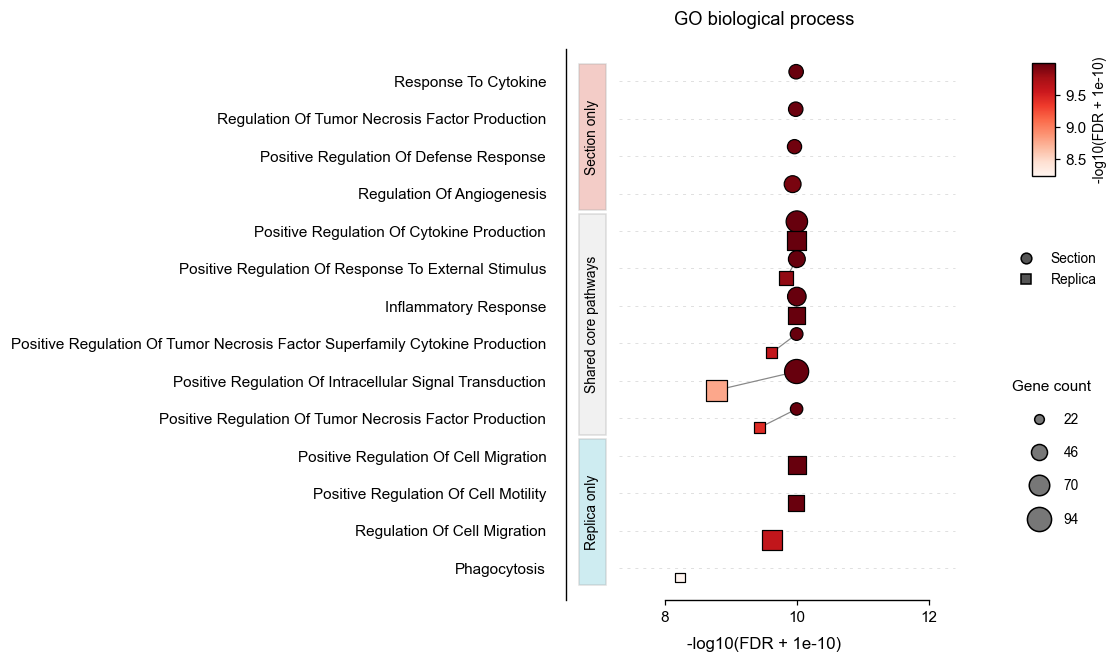

In [6]:
# 中文：绘制 GO BP 对比图。
# English: Plot the GO BP comparison.
bp_display = plot_go('BP','Figure4i_GO_BP')


## Extended Data Figure 1c — Gene detection versus abundance

For each gene and method, abundance is the mean raw count across all corresponding spots and detection is the fraction with count > 0. The original logistic fits are retained, without confidence bands.

中文：Section 和 Replica 分别使用其两种条件合并后的原始计数，独立剔除本组完全未检出的基因；横轴为 `log10(mean raw count + 1e-4)`。

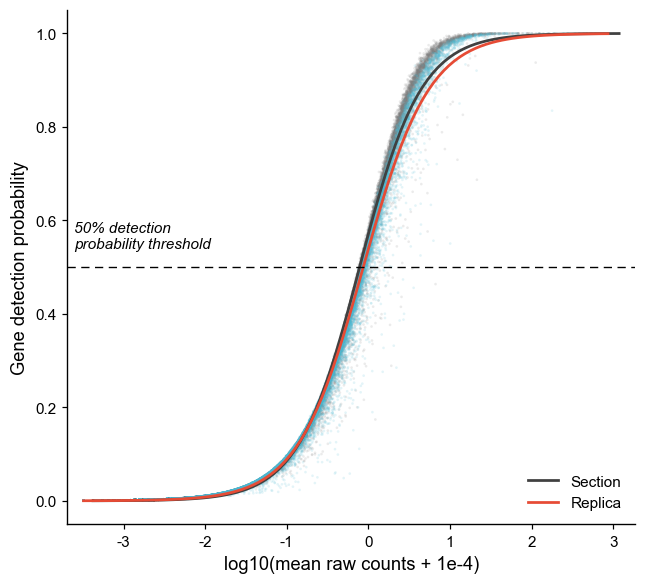

In [7]:
# 中文：用每基因原始计数摘要计算检出率并拟合 Logistic 曲线。
# English: Calculate detection fractions from raw-count summaries and fit logistic curves.
detection=read_table('gene_detection.csv.gz')
detection=detection[detection.mean_raw_count>0].copy()
detection['log_mean']=np.log10(detection.mean_raw_count+1e-4)
detection['fraction']=detection.detected_spots/detection.n_spots
fig,ax=plt.subplots(figsize=(6.3,5.7))
for method,point,line,label in [('section','#7F7F7F','#404040','Section'),('replica','#4DBBD5','#E64B35','Replica')]:
    d=detection[detection.method==method]
    sns.regplot(data=d,x='log_mean',y='fraction',logistic=True,ci=None,
                scatter_kws={'s':3,'alpha':.15,'color':point,'edgecolor':'none','rasterized':True},
                line_kws={'color':line,'lw':1.8,'label':label},ax=ax)
xmin=detection.log_mean.min()-.2;xmax=detection.log_mean.max()+.2
ax.set_xlim(xmin,xmax);ax.set_ylim(-.05,1.05)
ax.axhline(.5,color='black',ls=(0,(6,4)),lw=.9)
ax.text(xmin+.08,.54,'50% detection\nprobability threshold',fontsize=10,fontstyle='italic')
ax.set_xlabel('log10(mean raw counts + 1e-4)',fontsize=12)
ax.set_ylabel('Gene detection probability',fontsize=12)
ax.legend(loc='lower right',fontsize=10)
fig.subplots_adjust(left=.15,right=.97,bottom=.15,top=.97)
finish(fig,'Extended1c_gene_detection')


## Extended Data Figure 1d–e — Transcript-length associations

Linear counts normalized to 10,000 per spot are averaged over Section captures (batches 1 and 3) and Replica captures (2 and 4). Genes require mean > 0.05 in both methods and a positive value in the frozen length annotation. LOWESS curves follow the original analysis.

中文：使用每spot归一化至10,000的线性表达值，结合随附基因长度注释，按表达阈值筛选后绘制LOWESS曲线。

11,298 genes retained by the original expression/annotation rule.


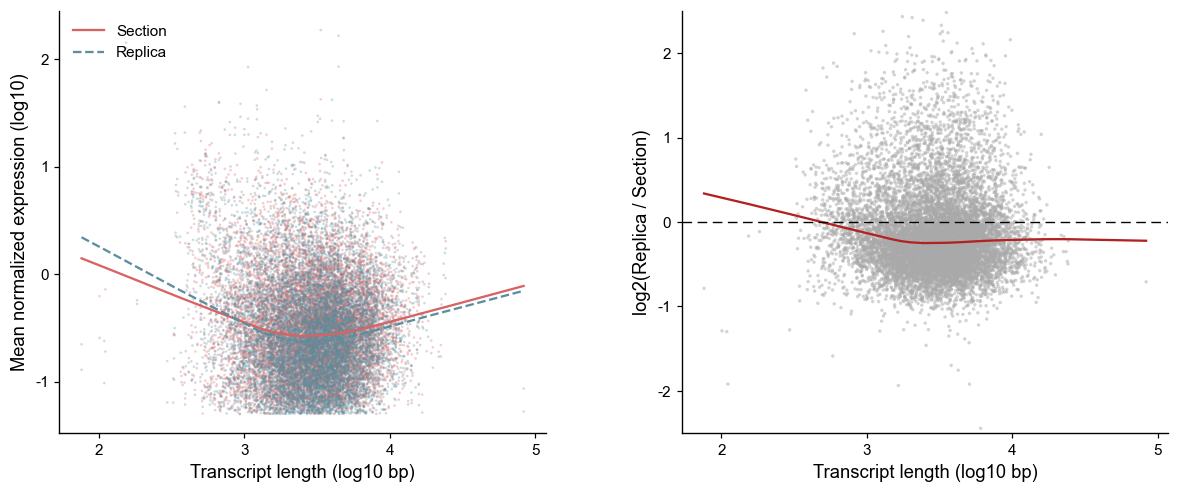

In [8]:
# 中文：合并基因长度并展示平均表达及 Replica/Section 比值。
# English: Combine gene lengths with mean expression and plot expression and Replica/Section ratios.
length_data=read_table('transcript_length_expression.csv.gz')
length_data=length_data[(length_data.Exp_Section>.05)&(length_data.Exp_Replica>.05)&(length_data.Length>0)].copy()
length_data['log_length']=np.log10(length_data.Length)
length_data['ratio']=np.log2(length_data.Exp_Replica/length_data.Exp_Section)
fig,axes=plt.subplots(1,2,figsize=(11.2,4.8))
for method,color,style in [('Section','#D76364','-'),('Replica','#5C8E9E','--')]:
    y=np.log10(length_data['Exp_'+method])
    axes[0].scatter(length_data.log_length,y,s=3,color=color,alpha=.3,edgecolors='none',rasterized=True)
    smooth=lowess(y,length_data.log_length,frac=2/3,it=3)
    axes[0].plot(smooth[:,0],smooth[:,1],color=color,ls=style,lw=1.5,label=method)
axes[0].set_ylabel('Mean normalized expression (log10)',fontsize=12)
axes[0].set_yticks([-1,0,1,2]);axes[0].legend(loc='upper left')
axes[1].scatter(length_data.log_length,length_data.ratio,s=5,color='#A9A9A9',alpha=.5,edgecolors='none',rasterized=True)
smooth=lowess(length_data.ratio,length_data.log_length,frac=2/3,it=3)
axes[1].plot(smooth[:,0],smooth[:,1],color='#B22222',lw=1.5)
axes[1].axhline(0,color='black',ls=(0,(7,4)),lw=.9)
axes[1].set_ylabel('log2(Replica / Section)',fontsize=12)
axes[1].set_ylim(-2.5,2.5)
for ax in axes:
    ax.set_xlabel('Transcript length (log10 bp)',fontsize=12);ax.set_xticks([2,3,4,5])
fig.subplots_adjust(left=.08,right=.98,bottom=.16,top=.96,wspace=.28)
print(f'{len(length_data):,} genes retained by the original expression/annotation rule.')
finish(fig,'Extended1d_e_transcript_length',axes)


In [9]:
# 中文：从固定控制点计算中心线及带方向距离。
# English: Compute centerlines and signed distances from the fixed control points.
spatial=read_table('sham_spatial_expression.csv.gz',dtype={'batch':str})
control=read_table('centerline_control_points.csv',dtype={'batch':str})
lines={}
spatial['signed_distance_spots']=np.nan
for batch in ['1','2']:
    pts=control[control.batch==batch].sort_values('point_order')[['x','y']].to_numpy()
    t=np.r_[0,np.cumsum(np.linalg.norm(np.diff(pts,axis=0),axis=1))]
    assert np.all(np.diff(t)>0)
    tt=np.linspace(0,t[-1],500)
    line=np.column_stack([make_interp_spline(t,pts[:,j],k=2)(tt) for j in [0,1]])
    lines[batch]=line
    mask=spatial.batch==batch;coords=spatial.loc[mask,['x','y']].to_numpy()
    dist,indices=cKDTree(line).query(coords)
    tangent=np.gradient(line,axis=0);tangent/=np.linalg.norm(tangent,axis=1,keepdims=True)
    delta=coords-line[indices]
    along=np.einsum('ij,ij->i',delta,tangent[indices])
    normal=np.column_stack([tangent[indices,1],-tangent[indices,0]])
    sign=np.sign(np.einsum('ij,ij->i',delta,normal));sign[sign==0]=1
    valid=(dist<=6)&(np.abs(along)<=1.5)
    spatial.loc[mask,'signed_distance_spots']=np.where(valid,dist*sign,np.nan)
display(spatial.groupby('batch').agg(total_spots=('spot_id','size'),band_spots=('signed_distance_spots','count')))


,total_spots,band_spots
batch,,
1,1682,317
2,2220,298


## Extended Data Figure 1f — Sham expression maps and centerline bands

The Hpca maps retain native coordinates. Insets show absolute distance to the quadratic centerline within a six-spot band; endpoint tangential displacement is limited to 1.5 spot units.

中文：使用原控制点和距离算法，展示完整 Sham 样本及用于表达曲线的空间带。距离色条单位为 spot；放大区域不改变坐标或表达值。

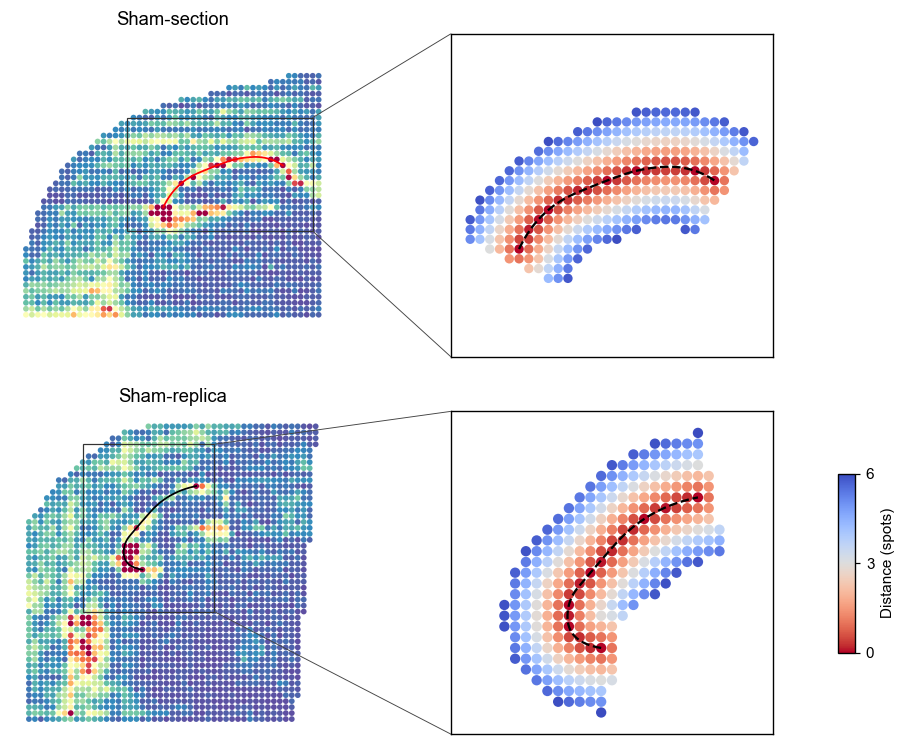

In [10]:
# 中文：绘制 Hpca 空间图与中心线距离放大图。
# English: Plot Hpca spatial maps and enlarged centerline-distance bands.
fig,axes=plt.subplots(2,2,figsize=(8.9,7.4))
norm=Normalize(*np.percentile(spatial.Hpca,[1,99]))
for row,(batch,label) in enumerate([('1','Sham-section'),('2','Sham-replica')]):
    d=spatial[spatial.batch==batch];coords=d[['x','y']].to_numpy();line=lines[batch]
    ax=axes[row,0]
    collection=PatchCollection([Circle(xy,.48) for xy in coords],cmap='Spectral_r',norm=norm,linewidths=0)
    collection.set_array(d.Hpca.to_numpy());ax.add_collection(collection)
    ax.plot(line[:,0],line[:,1],color='red' if batch=='1' else 'black',lw=1.15)
    center=(coords.min(0)+coords.max(0))/2
    ax.set_xlim(center[0]-27,center[0]+27);ax.set_ylim(center[1]+27,center[1]-27)
    ax.set_aspect('equal');ax.axis('off');ax.set_title(label,fontsize=12,pad=6)
    selected=d[d.signed_distance_spots.notna()];xy=selected[['x','y']].to_numpy()
    lo=xy.min(0)-1;hi=xy.max(0)+1
    ax.add_patch(Rectangle(lo,*(hi-lo),fill=False,lw=.8,edgecolor='#333333'))
    zoom=axes[row,1]
    band=PatchCollection([Circle(p,.48) for p in xy],cmap='coolwarm_r',norm=Normalize(0,6),linewidths=0)
    band.set_array(np.abs(selected.signed_distance_spots));zoom.add_collection(band)
    zoom.plot(line[:,0],line[:,1],color='black',ls='--',lw=1.5)
    midpoint=(lo+hi)/2;half=max(hi-lo)/2+1
    zoom.set_xlim(midpoint[0]-half,midpoint[0]+half);zoom.set_ylim(midpoint[1]+half,midpoint[1]-half)
    zoom.set_aspect('equal');zoom.set_xticks([]);zoom.set_yticks([])
    zoom.spines[['top','right']].set_visible(True)
    for start,end in [(hi*np.array([1,0])+lo*np.array([0,1]),(0,1)),(hi,(0,0))]:
        fig.add_artist(ConnectionPatch(start,end,coordsA='data',coordsB='axes fraction',axesA=ax,axesB=zoom,color='#444444',lw=.6))
fig.subplots_adjust(left=.03,right=.88,bottom=.08,top=.94,wspace=.12,hspace=.17)
cax=fig.add_axes([.91,.18,.018,.22]);cb=fig.colorbar(band,cax=cax,ticks=[0,3,6]);cb.set_label('Distance (spots)',fontsize=10)
finish(fig,'Extended1f_centerline_spatial',axes.ravel())


## Extended Data Figure 1g — Expression across the centerline

Raw expression is averaged in half-spot bins. Curves use Gaussian smoothing (sigma = 1 bin), quadratic interpolation, and the original 100-µm spot pitch. Points represent binned measurements; lines represent smoothed profiles.

中文：按0.5个spot分箱计算原始计数均值，空分箱取0；经高斯平滑和二次插值绘制曲线，距离按100 µm的spot间距换算。

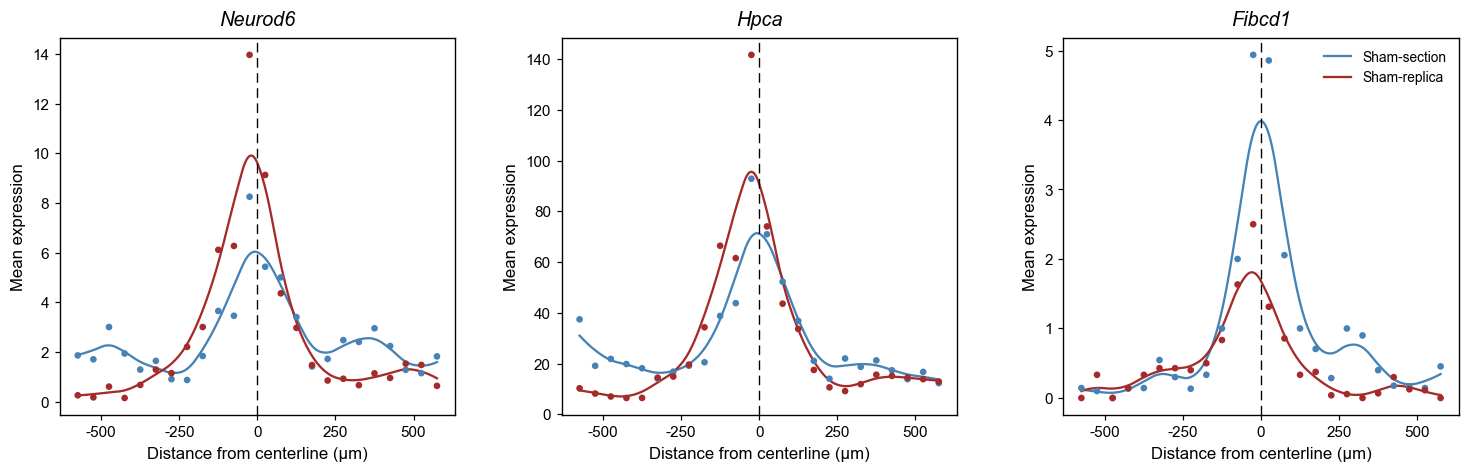

In [11]:
# 中文：绘制三个基因的测量均值和中心线表达曲线。
# English: Plot measured bin means and smoothed centerline profiles for three genes.
genes=['Neurod6','Hpca','Fibcd1'];bins=np.arange(-6,6.5,.5);centers=bins[:-1]+.25
profiles=[]
fig,axes=plt.subplots(1,3,figsize=(13.6,4.7))
for ax,gene in zip(axes,genes):
    for batch,label,color in [('1','Sham-section','steelblue'),('2','Sham-replica','brown')]:
        d=spatial[(spatial.batch==batch)&spatial.signed_distance_spots.notna()].copy()
        d['distance_bin']=pd.cut(d.signed_distance_spots,bins=bins,labels=centers)
        y=d.groupby('distance_bin',observed=False)[gene].mean().fillna(0).to_numpy()
        x=centers*100
        dense_x=np.linspace(x.min(),x.max(),1000)
        smooth=np.clip(make_interp_spline(x,gaussian_filter1d(y,sigma=1),k=2)(dense_x),0,None)
        ax.scatter(x,y,s=19,color=color,edgecolors='none',zorder=3)
        ax.plot(dense_x,smooth,color=color,lw=1.5,label=label)
        profiles.append(pd.DataFrame({'gene':gene,'batch':batch,'distance_um':x,'mean_raw_count':y}))
    ax.axvline(0,color='black',ls=(0,(7,4)),lw=.9)
    ax.set_title(gene,fontstyle='italic',fontsize=13,pad=8)
    ax.set_xlabel('Distance from centerline (µm)',fontsize=11)
    ax.set_ylabel('Mean expression',fontsize=11)
    ax.spines[['top','right']].set_visible(True)
    ax.set_xticks([-500,-250,0,250,500])
axes[-1].legend(loc='upper right',fontsize=9)
fig.subplots_adjust(left=.055,right=.99,bottom=.17,top=.90,wspace=.27)
profile_means=pd.concat(profiles,ignore_index=True)
finish(fig,'Extended1g_centerline_profiles',axes)


## Extended Data Figure 2a–b — MA plots

The x coordinate is the equal-condition mean of linear normalized expression, obtained by reversing `log1p` in the preprocessed object's `raw.X`. Colors use the complete fitted statistics. Off-scale fold changes are indicated with triangles; no genes are removed for the MA display.

中文：基因过滤排除Gm数字编号基因，Section/Replica的上调数分别为1494/1144。横轴为每万计数归一化表达，纵轴为原 Wilcoxon 分析报告的 log2FC。

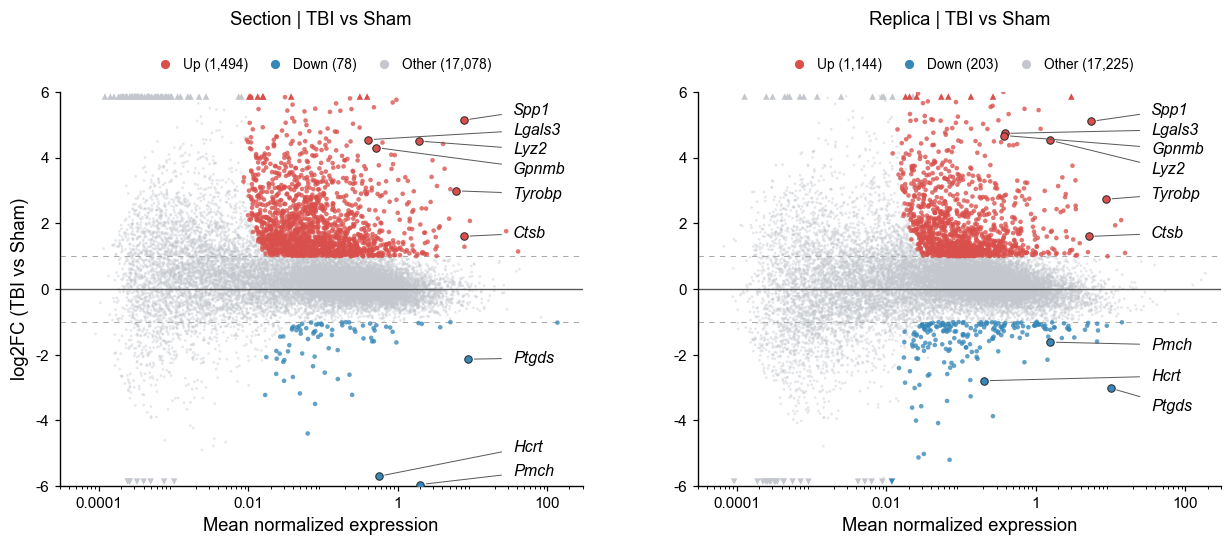

In [12]:
# 中文：绘制两个 MA 图并标注指定共同差异基因。
# English: Draw both MA plots and label the specified shared differential genes.
LABEL_UP=['Spp1','Lyz2','Ctsb','Tyrobp','Lgals3','Gpnmb']
LABEL_DOWN=['Ptgds','Pmch','Hcrt']
COLORS={'Up':'#D94F4B','Down':'#3787B8','Other':'#C4C8CE'}
fig,axes=plt.subplots(1,2,figsize=(11.6,5.6))
for ax,method,title in zip(axes,['section','replica'],['Section','Replica']):
    d=de[de.method==method];selected=d.set_index('names')
    ax.set_xscale('log');ax.set_xlim(.00003,300);ax.set_ylim(-6,6)
    ax.xaxis.set_major_locator(FixedLocator([.0001,.01,1,100]))
    ax.xaxis.set_major_formatter(FixedFormatter(['0.0001','0.01','1','100']))
    ax.set_yticks([-6,-4,-2,0,2,4,6]);ax.axhline(0,color='#555555',lw=.9)
    for y in [-1,1]:ax.axhline(y,color='#AAAAAA',lw=.7,ls=(0,(5,5)))
    for status in ['Other','Up','Down']:
        chosen=d.status==status;inside=chosen&d.logfoldchanges.between(-6,6)
        ax.scatter(d.loc[inside,'A_mean_normalized_counts'],d.loc[inside,'logfoldchanges'],
                   s=3.2 if status=='Other' else 9,color=COLORS[status],alpha=.42 if status=='Other' else .78,
                   edgecolors='none',rasterized=True,zorder=1 if status=='Other' else 2)
        for mask,marker,y in [(chosen&(d.logfoldchanges>6),'^',5.86),(chosen&(d.logfoldchanges< -6),'v',-5.86)]:
            ax.scatter(d.loc[mask,'A_mean_normalized_counts'],np.full(mask.sum(),y),s=18,marker=marker,color=COLORS[status],edgecolors='none',zorder=3)
    up_order=sorted(LABEL_UP,key=lambda gene:selected.loc[gene,'logfoldchanges'],reverse=True)
    label_y=dict(zip(up_order,[5.45,4.85,4.25,3.65,2.90,1.70]))
    label_y.update({'Ptgds':-2.10,'Hcrt':-4.80,'Pmch':-5.55} if method=='section' else {'Pmch':-1.70,'Hcrt':-2.65,'Ptgds':-3.55})
    for gene in LABEL_UP+LABEL_DOWN:
        r=selected.loc[gene];xy=(r.A_mean_normalized_counts,r.logfoldchanges)
        ax.scatter(*xy,s=24,color=COLORS[r.status],edgecolor='#282828',lw=.65,zorder=5)
        ax.annotate(gene,xy=xy,xytext=(35,label_y[gene]),fontsize=10.5,fontstyle='italic',ha='left',va='center',
                     arrowprops={'arrowstyle':'-','color':'#595959','lw':.65,'shrinkA':5.5,'shrinkB':4},zorder=6)
    ax.set_xlabel('Mean normalized expression',fontsize=12)
    ax.set_title(title+' | TBI vs Sham',fontsize=12,pad=44)
    counts=d.status.value_counts();handles=[Line2D([],[],marker='o',ls='',color=COLORS[s],markersize=5) for s in ['Up','Down','Other']]
    ax.legend(handles,[f'{s} ({counts[s]:,})' for s in ['Up','Down','Other']],
               loc='lower center',bbox_to_anchor=(.5,1.02),ncol=3,fontsize=9,handletextpad=.3,columnspacing=1)
axes[0].set_ylabel('log2FC (TBI vs Sham)',fontsize=12)
fig.subplots_adjust(left=.075,right=.985,bottom=.15,top=.79,wspace=.22)
finish(fig,'Extended2a_b_MA',axes)


## Extended Data Figure 2c — Concordance of fold changes

Compare genes measured by both methods, retaining the original |log2FC| ≤ 10 rule in both comparisons. Labels identify the five largest Section–Replica deviations in each shared differential-expression category.

中文：使用差异基因表计算Pearson相关系数和共同上、下调集合；显示范围为±8，回归使用筛选后的全部共有基因。

Pearson R = 0.600314; 18,048 common genes included.


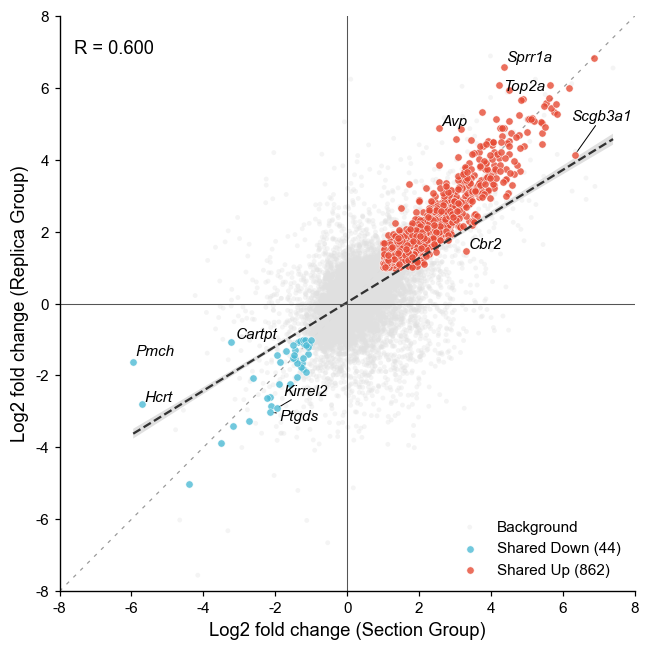

In [13]:
# 中文：计算并展示共同基因的 fold-change 一致性。
# English: Calculate and display fold-change concordance for shared genes.
a=de[de.method=='section'][['names','logfoldchanges','pvals_adj']]
b=de[de.method=='replica'][['names','logfoldchanges','pvals_adj']]
concordance=a.merge(b,on='names',suffixes=('_sec','_rep'),validate='one_to_one')
concordance=concordance[(concordance.logfoldchanges_sec.abs()<=10)&(concordance.logfoldchanges_rep.abs()<=10)].copy()
up=(concordance.pvals_adj_sec<.05)&(concordance.pvals_adj_rep<.05)&(concordance.logfoldchanges_sec>1)&(concordance.logfoldchanges_rep>1)
down=(concordance.pvals_adj_sec<.05)&(concordance.pvals_adj_rep<.05)&(concordance.logfoldchanges_sec< -1)&(concordance.logfoldchanges_rep< -1)
concordance['category']=np.select([up,down],['Shared Up','Shared Down'],default='Background')
r,p=stats.pearsonr(concordance.logfoldchanges_sec,concordance.logfoldchanges_rep)
assert up.sum()==862 and down.sum()==44
concordance['deviation']=(concordance.logfoldchanges_rep-concordance.logfoldchanges_sec).abs()
labels=pd.concat([concordance[concordance.category==category].nlargest(5,'deviation') for category in ['Shared Up','Shared Down']])
fig,ax=plt.subplots(figsize=(6.5,6.3))
for category,color,size in [('Background','#E0E0E0',10),('Shared Down','#4DBBD5',23),('Shared Up','#E64B35',23)]:
    d=concordance[concordance.category==category]
    ax.scatter(d.logfoldchanges_sec,d.logfoldchanges_rep,s=size,color=color,
               alpha=.35 if category=='Background' else .8,edgecolors='none' if category=='Background' else 'white',
               linewidths=.4,label=category if category=='Background' else f'{category} ({len(d)})',rasterized=True,zorder=2)
sns.regplot(data=concordance,x='logfoldchanges_sec',y='logfoldchanges_rep',scatter=False,
            seed=42,line_kws={'color':'#333333','lw':1.5,'ls':'--'},ax=ax)
ax.set_xlim(-8,8);ax.set_ylim(-8,8);ax.set_aspect('equal')
texts=[ax.text(row.logfoldchanges_sec,row.logfoldchanges_rep+(.85 if row.names=='Scgb3a1' else 0),row.names,fontsize=10,fontstyle='italic',zorder=5) for row in labels.itertuples()]
np.random.seed(42)
adjust_text(texts,ax=ax,target_x=labels.logfoldchanges_sec.to_numpy(),target_y=labels.logfoldchanges_rep.to_numpy(),
            iter_lim=150,arrowprops={'arrowstyle':'-','color':'black','lw':.65})
ax.plot([-8,8],[-8,8],color='#999999',ls=(0,(3,5)),lw=.8,zorder=0)
ax.axhline(0,color='#555555',lw=.7);ax.axvline(0,color='#555555',lw=.7)
ax.text(.025,.96,f'R = {r:.3f}',transform=ax.transAxes,va='top',fontsize=12)
ax.legend(loc='lower right',fontsize=10)
ax.set_xlabel('Log2 fold change (Section Group)',fontsize=12)
ax.set_ylabel('Log2 fold change (Replica Group)',fontsize=12)
fig.subplots_adjust(left=.16,right=.98,bottom=.15,top=.98)
print(f'Pearson R = {r:.6f}; {len(concordance):,} common genes included.')
finish(fig,'Extended2c_fold_change_concordance')


## Extended Data Figure 2d–e — GO cellular component and molecular function

Use the same term-selection rule, group markers, overlap sizes and FDR display transformation as Figure 4i. Both panels encode the FDR score by position and color.

中文：分别展示GO CC和GO MF；使用随附的富集统计，圆形和方形分别表示Section与Replica。

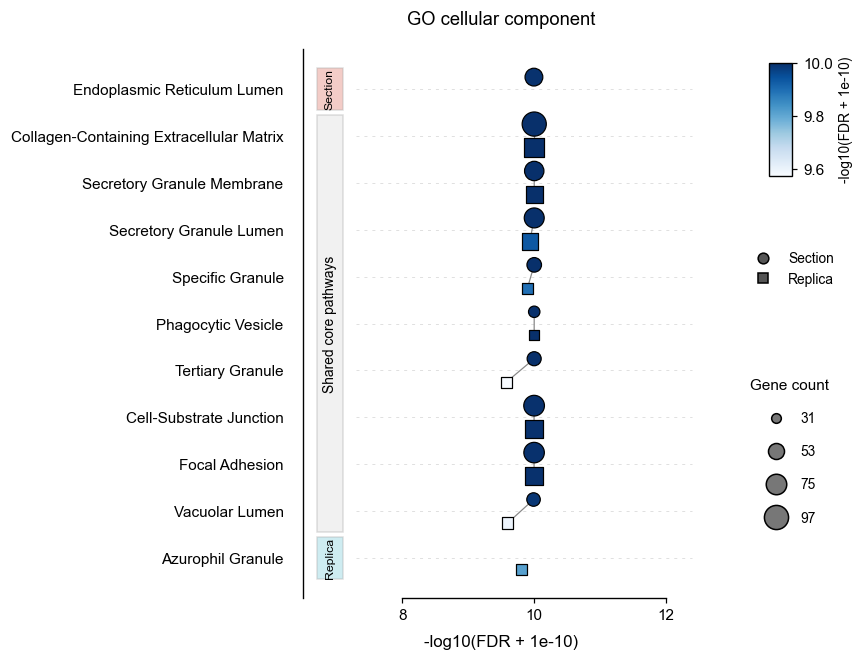

In [14]:
# 中文：绘制 GO CC 对比图。
# English: Plot the GO CC comparison.
cc_display = plot_go('CC','Extended2d_GO_CC')


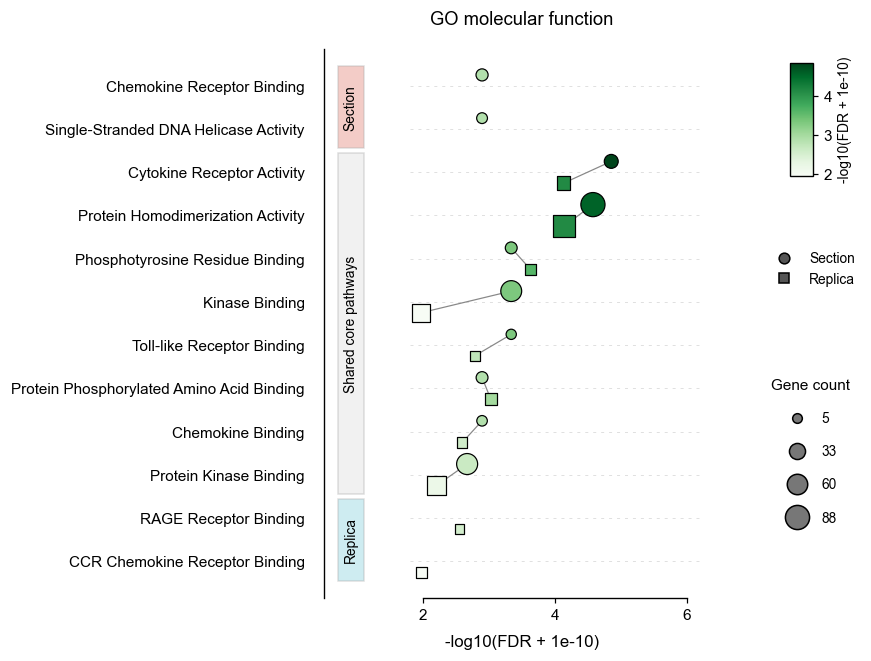

In [15]:
# 中文：绘制 GO MF 对比图。
# English: Plot the GO MF comparison.
mf_display = plot_go('MF','Extended2e_GO_MF')


## Optional AnnData reconstruction

The following cells define how the compact tables were obtained. They are not required to view or reproduce the figures above. To verify them against the larger inputs, place the original matrices in `raw_data/` with the relative layout listed in the README and set `VERIFY_H5AD = True`.

中文：以下代码保留 h5ad 到绘图数据的计算过程。默认不读取大型文件；开启验证后，只读加载输入并与随附数据逐项比较，不重新聚类、不覆盖原数据。

In [16]:
# 中文：设置可选 h5ad 验证开关并定义按原方法重新计算差异结果的函数。
# English: Configure optional AnnData validation and define the original differential-expression calculation.
VERIFY_H5AD = False
RAW_DATA = Path('raw_data')

def reconstruct_de(method):
    import scanpy as sc
    from scipy import sparse
    adata=sc.read_h5ad(RAW_DATA/f'{method} vs'/f'{method} vs_pp.h5ad')
    assert adata.raw is not None
    batches=adata.obs.batch.astype(str)
    adata.obs['comparison']=pd.Categorical(batches.map({'1':'Sham','2':'TBI'}))
    sc.tl.rank_genes_groups(adata,groupby='comparison',groups=['TBI'],reference='Sham',
                           method='wilcoxon',use_raw=True,tie_correct=False,corr_method='benjamini-hochberg')
    ranked=sc.get.rank_genes_groups_df(adata,group='TBI')
    excluded=re.compile(r'^mt-|^Gm\d+(?:-\d+)?$|-ps|Rik$|^Hba-|^Hbb-|^Rp[sl]\d+',re.I)
    ranked=ranked[~ranked.names.str.contains(excluded)].copy()
    x=adata.raw.X.copy()
    if sparse.issparse(x):x.data=np.expm1(x.data)
    else:x=np.expm1(x)
    abundance=pd.DataFrame({'names':adata.raw.var_names})
    for batch,label in [('1','Sham'),('2','TBI')]:
        abundance['mean_norm_'+label]=np.asarray(x[batches.to_numpy()==batch].mean(axis=0)).ravel()
    abundance['A_mean_normalized_counts']=(abundance.mean_norm_Sham+abundance.mean_norm_TBI)/2
    return ranked.merge(abundance,on='names',validate='one_to_one')

if VERIFY_H5AD:
    for method in ['section','replica']:
        actual=reconstruct_de(method).set_index('names').sort_index()
        reference=de[de.method==method].set_index('names').sort_index()
        assert actual.index.equals(reference.index)
        for field in ['scores','logfoldchanges','pvals','pvals_adj','mean_norm_Sham','mean_norm_TBI','A_mean_normalized_counts']:
            assert np.allclose(actual[field],reference[field],rtol=2e-5,atol=1e-10),field
    print('Differential-expression and MA inputs match the supplied tables.')
else:
    print('Using the included fitted statistics; optional AnnData validation is disabled.')


Using the included fitted statistics; optional AnnData validation is disabled.


In [17]:
# 中文：保留原始计数、标准化表达和空间坐标的提取与验证步骤。
# English: Retain extraction and validation of raw-count summaries, scaled expression and spatial coordinates.
def validate_expression_inputs():
    import scanpy as sc
    from scipy import sparse
    def dense(x):return x.toarray() if sparse.issparse(x) else np.asarray(x)
    for method in ['section','replica']:
        raw=sc.read_h5ad(RAW_DATA/f'{method} vs'/f'{method} vs.h5ad')
        expected=read_table('gene_detection.csv.gz')
        expected=expected[expected.method==method].set_index('Gene').loc[raw.var_names]
        assert np.allclose(np.asarray(raw.X.mean(axis=0)).ravel(),expected.mean_raw_count)
        assert np.array_equal(np.asarray((raw.X>0).sum(axis=0)).ravel(),expected.detected_spots)
        assert (expected.n_spots==raw.n_obs).all()
        del raw
    raw=sc.read_h5ad(RAW_DATA/'TBI-4/TBI-4.h5ad')
    batch=raw.obs.batch.astype(str).to_numpy()
    expected=read_table('transcript_length_expression.csv.gz').set_index('Gene').loc[raw.var_names]
    normalized=raw.X.copy()
    totals=np.asarray(normalized.sum(axis=1)).ravel()
    assert (totals>0).all()
    if sparse.issparse(normalized):normalized=normalized.multiply((10000/totals)[:,None]).tocsr()
    else:normalized=normalized*(10000/totals)[:,None]
    for method,groups in [('Section',['1','3']),('Replica',['2','4'])]:
        actual=np.asarray(normalized[np.isin(batch,groups)].mean(axis=0)).ravel()
        assert np.allclose(actual,expected['Exp_'+method])
    mask=np.isin(batch,['1','2'])
    expected=read_table('sham_spatial_expression.csv.gz',dtype={'batch':str}).set_index('spot_id').loc[raw.obs_names[mask]]
    assert np.array_equal(raw.obsm['spatial'][mask],expected[['x','y']].to_numpy())
    assert np.allclose(dense(raw[mask,['Neurod6','Hpca','Fibcd1']].X),expected[['Neurod6','Hpca','Fibcd1']])
    del raw
    preprocessed=sc.read_h5ad(RAW_DATA/'TBI-4/TBI-4_pp.h5ad')
    mask=preprocessed.obs.batch.astype(str).isin(['3','4']).to_numpy()
    expected=read_table('marker_expression.csv.gz',dtype={'batch':str,'leiden':str}).set_index('spot_id').loc[preprocessed.obs_names[mask]]
    assert np.array_equal(preprocessed.obs.leiden.astype(str).to_numpy()[mask],expected.leiden.to_numpy())
    assert np.allclose(dense(preprocessed[mask,marker_order].X),expected[marker_order])
    print('Raw summaries, coordinates, cluster labels and marker-expression values match.')

if VERIFY_H5AD:
    validate_expression_inputs()
else:
    print('The included tables provide all required expression and coordinate inputs.')


The included tables provide all required expression and coordinate inputs.


## Data and software reference

The data index records source-object hashes and the panel map identifies the source cells used for this implementation. `raw` in a preprocessed AnnData object denotes log-normalized expression here; it is distinct from the unprocessed count matrix.

中文：下方列出数据来源、面板对应关系和当前软件版本。保存的 notebook 输出可直接用于浏览。

In [18]:
# 中文：显示数据来源、面板对应表及软件版本。
# English: Display data provenance, panel mapping and software versions.
from importlib.metadata import version
display(read_table('panel_sources.csv'))
display(read_table('input_provenance.csv')[['source','role','shape','sha256']])
packages=['numpy','pandas','scipy','matplotlib','seaborn','statsmodels','matplotlib-venn','adjustText']
display(pd.DataFrame({'Package':packages,'Version':[version(p) for p in packages]}))


,Panel,Source notebook,Source cells (1-based),Analysis
0,Figure 4g,TBI-4.ipynb,1,Corrected DE membership from the final MA work...
1,Figure 4h,get_adata.ipynb,76–78,Saved marker order; batches 3/4 in the four-ca...
2,Figure 4i,TBI-4.ipynb,2–3,Archived GO BP statistics and original display...
3,Extended Data 1c,TBI-4.ipynb,8,Raw Section/Replica count matrices
4,Extended Data 1d–e,get_adata.ipynb,81–82,"Pooled linear normalized means (10,000 per spo..."
5,Extended Data 1f,LWMH.ipynb,"6, 8",Fixed Sham centerlines and distance-band algor...
6,Extended Data 1g,LWMH.ipynb,11,Raw-count half-spot binning; 100 µm pitch
7,Extended Data 2a–b,MA_Gm_corrected_comparison.ipynb,3–4,Corrected Gm filter; frozen fitted statistics ...
8,Extended Data 2c,TBI-4.ipynb,7,Correlation and labels from corrected shared-g...
9,Extended Data 2d,TBI-4.ipynb,5,GO CC color encodes the original FDR display s...


,source,role,shape,sha256
0,section vs/section vs_pp.h5ad,MA abundance and differential-expression recon...,"(3108, 3591)",ee4b433779b590e4a914f75b72695fe5ba04fb88f62c67...
1,section vs/DEG_TBI_vs_Sham_section_Cleaned.csv,Fitted differential-expression statistics used...,NaN,1e1b437b40ea3f50b5f1c717ef7cc412448703d4d786ae...
2,section vs/section vs.h5ad,Raw-count gene-detection statistics,"(3108, 31082)",8e0957dcc516d9194e349ffd8038cb643d6cf2cb7db24a...
3,replica vs/replica vs_pp.h5ad,MA abundance and differential-expression recon...,"(4496, 3551)",ddfc205b9f35b7e800d09545ca0ec0c1feae8aea917a9f...
4,replica vs/DEG_TBI_vs_Sham_replica_Cleaned.csv,Fitted differential-expression statistics used...,NaN,5d26a32cd0c6e11d6511d3e841b935222cc0c182136c15...
5,replica vs/replica vs.h5ad,Raw-count gene-detection statistics,"(4496, 30244)",63bb3ded3f63f11f58d45ddec525dba504ed19bc7dca68...
6,Venn_Analysis/Enrichment_Data/GO_BP_Top20_Enri...,Enrichr GO statistics for the Section and Repl...,NaN,8aa8bf69528bbda8964099088189a69ce7663a71ffb11f...
7,Venn_Analysis/Enrichment_Data/GO_CC_Top20_Enri...,Enrichr GO statistics for the Section and Repl...,NaN,e4431b8d2dbf9d3de3edfc0b62c12fa54d4767f7ab40e8...
8,Venn_Analysis/Enrichment_Data/GO_MF_Top20_Enri...,Enrichr GO statistics for the Section and Repl...,NaN,745163b6a33c8fd117906d7321b341c01d27d4d6723512...
9,TBI-4/figures/Batch3_Cluster3_Top30_Upregulate...,Original cluster-3 marker order; first 20 disp...,NaN,65f7007acab2226db324fcae29fc4fdd6cfa93c5e83536...


,Package,Version
0,numpy,2.2.6
1,pandas,2.3.3
2,scipy,1.15.3
3,matplotlib,3.10.8
4,seaborn,0.13.2
5,statsmodels,0.14.6
6,matplotlib-venn,1.1.2
7,adjustText,1.3.0
